# Logistic Regression
A linear classifier separating Higgs → γγ signal from the diphoton background, as the first machine-learning alternative to the tutorial cuts of notebook 02.

**Samples** (all after the notebook 01 preselection, restricted to 100 < m_γγ < 160 GeV)
- **Signal:** ggH → γγ Monte Carlo (`mc_343981`). 50% held out for testing; the other half is split 80/20 into training/validation.
- **Background for training:** real data, **period A** (80% train / 20% validation). In the 100-160 GeV window real data is > 99.9% background (~50 Higgs events vs ~96k events in A).
- **Test:** real data **B, C and D** (9.5 fb⁻¹) and the held-out MC. Neither is touched while training or choosing the cut.

**Rules that keep the result honest**
1. **m_γγ is not a feature.** Photon momenta enter only as pT/m_γγ, so the model cannot rebuild the mass (see notebook 04 for what happens otherwise).
2. **The score cut is chosen on validation samples only** (MC validation + data A validation), by maximising the expected significance.
3. **The Higgs is then measured in data B+C+D** with the same polynomial + Gaussian fit as the tutorial, now as a binned Poisson likelihood that gives a signal yield, a signal strength μ = N_fit / N_expected and a local significance.

In [1]:
import sys, json, warnings
import numpy as np
import matplotlib.pyplot as plt

sys.path.append("../src")
warnings.filterwarnings("ignore", message="Invalid or negative diphoton")

from dataset import load_all, LUMI_TEST
from features import FEATURES
from evaluate import fit_signal_shape, BINS, CENTRES, in_window
from classifier import training_set, score_all, evaluate, print_summary, save, FIG_DIR
from plotting import plot_fit

D = load_all()
for k in ["sig_train", "sig_val", "sig_test", "bkg_train", "bkg_val"]:
    print(f"{k:10s} {len(D[k]['myy']):>8d} events")
for p, d in D["data"].items():
    print(f"data {p}     {len(d['myy']):>8d} events (test)")
print(f"expected Higgs events in data B+C+D after preselection: {D['sig_test']['w'].sum():.0f}")

# Gaussian width of the Higgs peak from MC, fixed in every data fit
m0, SIGMA = fit_signal_shape(D["sig_test"]["myy"], np.abs(D["sig_test"]["w"]))
print(f"MC signal peak: mean {m0:.2f} GeV, sigma {SIGMA:.2f} GeV")

sig_train    370825 events
sig_val       92707 events
sig_test     463533 events
bkg_train     77099 events
bkg_val       19275 events
data B       341938 events (test)
data C       499912 events (test)
data D       807218 events (test)
expected Higgs events in data B+C+D after preselection: 454
MC signal peak: mean 124.99 GeV, sigma 2.34 GeV


## Input features
| group | features |
|---|---|
| photon kinematics (scale-free) | pT1/m_γγ, pT2/m_γγ, pT_γγ/m_γγ, \|η1\|, \|η2\|, Δφ, \|cos θ*\|, \|y_γγ\| |
| identification / isolation | tightID (×2), E_T^cone20 (×2), p_T^cone30 (×2) |
| jets (pT > 25 GeV, \|η\| < 2.5, JVT, ΔR(jet, γ) > 0.4) | number of jets, leading jet pT |

The jet cleaning is the overlap removal sketched in the README (`features.clean_jets`).

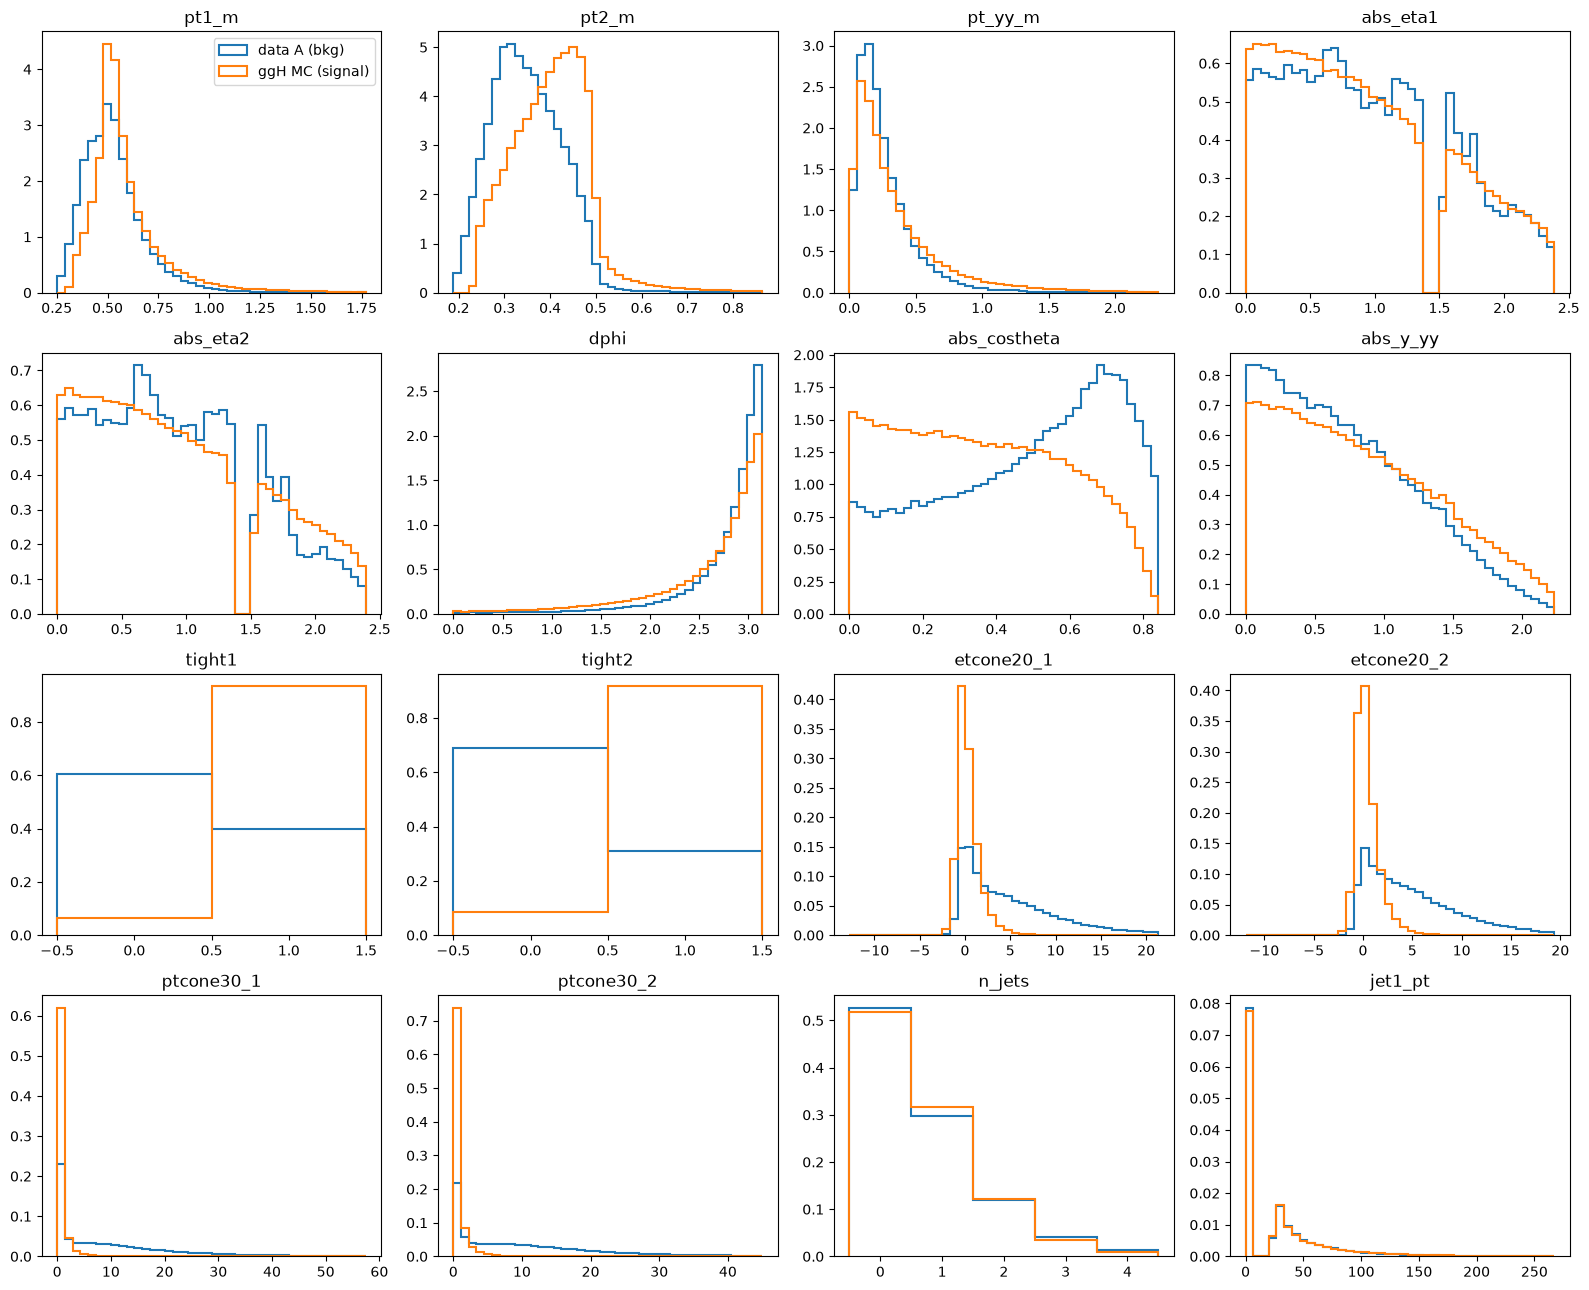

In [2]:
show = FEATURES
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, f in zip(axes.flat, show):
    s, b = D["sig_train"][f], D["bkg_train"][f]
    hi = np.quantile(np.r_[s, b], 0.995)
    lo = min(s.min(), b.min())
    bins = np.linspace(lo, hi, 41) if f not in ("tight1", "tight2", "n_jets") else np.arange(-0.5, max(hi, 1) + 1.5)
    ax.hist(b, bins, density=True, histtype="step", lw=1.5, label="data A (bkg)")
    ax.hist(s, bins, density=True, histtype="step", lw=1.5, weights=np.abs(D["sig_train"]["w"]), label="ggH MC (signal)")
    ax.set_title(f)
axes.flat[0].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "input_features.png", dpi=120)
plt.show()

The photon identification and isolation variables are by far the most separating: the background is dominated by jets faking photons (γ+jet, dijet), which are non-tight and surrounded by hadronic activity. The kinematic variables add a little more: Higgs photons are more central in |cos θ*| and the diphoton system recoils harder (pT_γγ/m_γγ).

## Training
Standardised features → L2-regularised logistic regression. Each class is reweighted to the same total weight (MC weights are tiny compared to the unit weight of data events). The regularisation strength `C` is picked on the validation set.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss, roc_auc_score

X_tr, y_tr, w_tr = training_set(D["sig_train"], D["bkg_train"])
X_va, y_va, w_va = training_set(D["sig_val"], D["bkg_val"])

scan = {}
for C in [1e-3, 1e-2, 1e-1, 1, 10]:
    m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))
    m.fit(X_tr, y_tr, logisticregression__sample_weight=w_tr)
    p = m.predict_proba(X_va)[:, 1]
    scan[C] = (log_loss(y_va, p, sample_weight=w_va), roc_auc_score(y_va, p, sample_weight=w_va), m)
    print(f"C = {C:<6g} val. log-loss = {scan[C][0]:.4f}   val. AUC = {scan[C][1]:.4f}")

best_C = min(scan, key=lambda c: scan[c][0])
logreg = scan[best_C][2]
print("chosen C =", best_C)

C = 0.001  val. log-loss = 0.2529   val. AUC = 0.9556


C = 0.01   val. log-loss = 0.2507   val. AUC = 0.9562


C = 0.1    val. log-loss = 0.2495   val. AUC = 0.9567


C = 1      val. log-loss = 0.2491   val. AUC = 0.9569


C = 10     val. log-loss = 0.2490   val. AUC = 0.9569
chosen C = 10


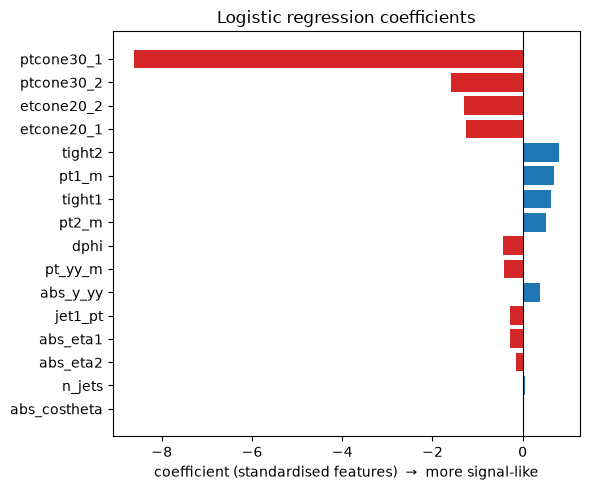

In [4]:
coef = logreg.named_steps["logisticregression"].coef_[0]
order = np.argsort(np.abs(coef))
plt.figure(figsize=(6, 5))
plt.barh(np.array(FEATURES)[order], coef[order], color=["C3" if c < 0 else "C0" for c in coef[order]])
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("coefficient (standardised features)  →  more signal-like")
plt.title("Logistic regression coefficients")
plt.tight_layout()
plt.savefig(FIG_DIR / "logreg_coefficients.png", dpi=150)
plt.show()

## Performance on the test samples

In [5]:
def diagnostics(name, sc, res, extra):
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))

    ax[0].plot(extra["fpr"], extra["tpr"], label=f"{name} (AUC = {res['AUC']:.3f})")
    ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
    ax[0].plot(1 - res["bkg_rej"], res["sig_eff"], "r*", ms=12, label="chosen cut")
    ax[0].set(xscale="log", xlim=(1e-3, 1), xlabel="Background efficiency (data B+C+D)",
              ylabel="Signal efficiency (MC test)", title="ROC")
    ax[0].legend()

    bins = np.linspace(0, 1, 51)
    ax[1].hist(sc["data_bcd"], bins, density=True, histtype="step", lw=1.5, label="data B+C+D (bkg)")
    ax[1].hist(sc["sig_test"], bins, density=True, histtype="step", lw=1.5,
               weights=np.abs(D["sig_test"]["w"]), label="ggH MC (signal)")
    ax[1].axvline(res["cut"], color="r", ls="--", label="chosen cut")
    ax[1].set(yscale="log", xlabel=f"{name} score", ylabel="Normalised", title="Score distribution")
    ax[1].legend()

    scan = extra["scan"]
    ax[2].plot(scan[:, 1], scan[:, 4], "-")
    best = scan[np.argmax(scan[:, 4])]
    ax[2].plot(best[1], best[4], "r*", ms=12, label=f"best: eff = {best[1]:.2f}, Z = {best[4]:.2f}")
    ax[2].set(xlabel="Signal efficiency of score cut (validation)",
              ylabel="Expected Asimov Z (120-130 GeV)", title="Cut choice on validation set")
    ax[2].legend()
    plt.tight_layout()
    return fig


def sculpting_check(name, sc, cut):
    """Does the cut change the SHAPE of the background m_yy spectrum?
    A smooth trend is fine (the polynomial absorbs it); a bump is not."""
    d = D["data_bcd"]
    h_all, _ = np.histogram(d["myy"], BINS)
    h_cut, _ = np.histogram(d["myy"][sc["data_bcd"] >= cut], BINS)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].step(CENTRES, h_all / h_all.sum(), where="mid", label="preselection")
    ax[0].step(CENTRES, h_cut / h_cut.sum(), where="mid", label=f"{name} cut")
    ax[0].set(xlabel=r"$m_{\gamma\gamma}$ [GeV]", ylabel="Normalised", title="Data B+C+D shape")
    ax[0].legend()
    eff = h_cut / h_all
    ax[1].errorbar(CENTRES, eff, yerr=np.sqrt(eff * (1 - eff) / h_all), fmt="k.")
    ax[1].axvspan(120, 130, color="C0", alpha=0.1, label="signal window")
    ax[1].set(xlabel=r"$m_{\gamma\gamma}$ [GeV]", ylabel="Fraction of data passing cut",
              title="Cut efficiency vs mass (contains the real Higgs too)")
    ax[1].legend()
    plt.tight_layout()
    return fig

--- Logistic regression ---
AUC (MC test vs data B+C+D)          0.9578
sig. eff. @ 1% / 5% bkg eff.          0.253 / 0.720
bkg. rejection @ 80% sig. eff.        0.9363
score cut (chosen on validation)      0.903
  signal efficiency / bkg rejection   0.597 / 0.9644
  data B+C+D events passing           58718
  expected Higgs events (MC)          271
  fitted Higgs events (m_H = 125)     263 ± 112
  signal strength mu                  0.97 ± 0.41
  fitted m_H                          125.31 ± 1.00 GeV
  local significance obs. / exp.      2.29 / 2.61 sigma
  corr(score, m_yy) in data           -0.1012


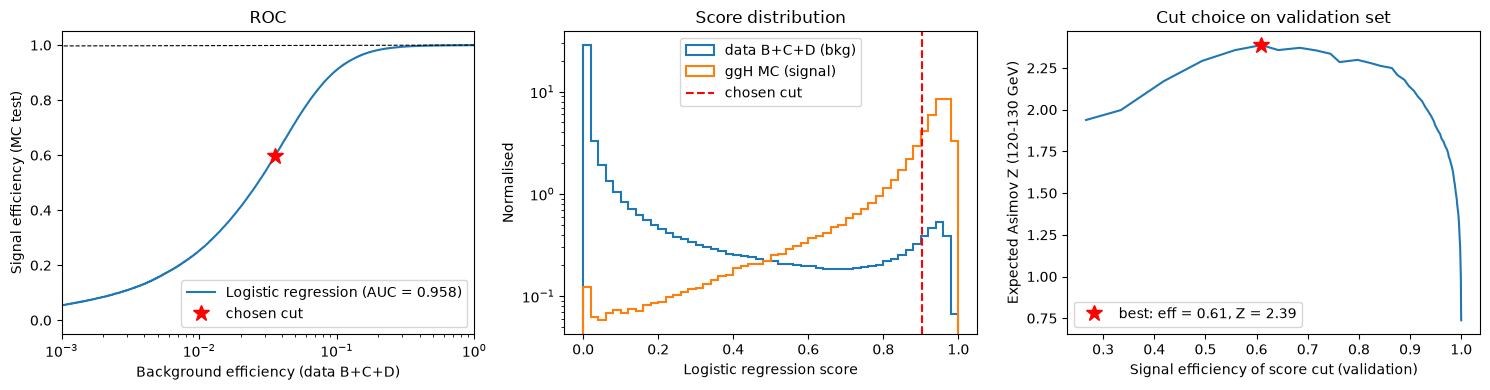

In [6]:
sc = score_all(logreg, D)
res, extra = evaluate(sc, D, SIGMA)
print_summary("Logistic regression", res)

diagnostics("Logistic regression", sc, res, extra)
plt.savefig(FIG_DIR / "logreg_performance.png", dpi=150)
plt.show()

## Does the cut sculpt the background?
If the classifier selects background events with a preferred mass, the "smooth polynomial" assumption of the fit breaks and a fake bump can appear. The right panel is the fraction of data passing the cut per GeV: a smooth trend is harmless, a localised bump around 125 GeV beyond what the real Higgs explains would not be.

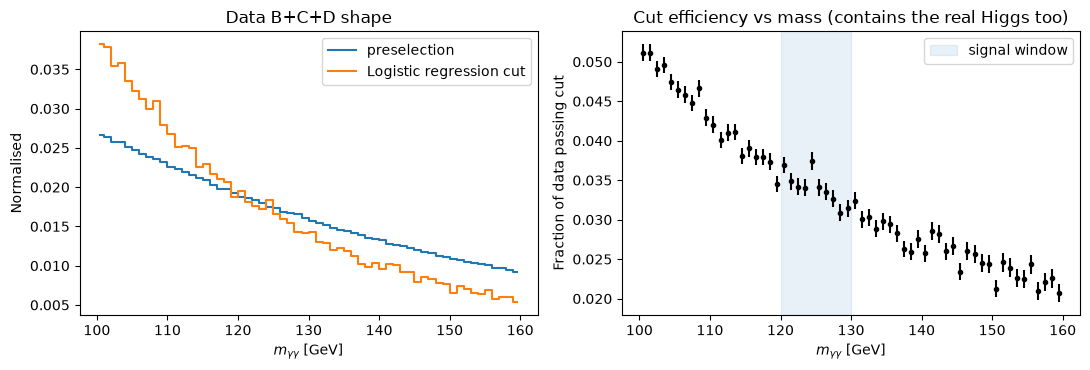

In [7]:
sculpting_check("Logistic regression", sc, res["cut"])
plt.savefig(FIG_DIR / "logreg_sculpting.png", dpi=150)
plt.show()

## Higgs fit in data B+C+D after the cut

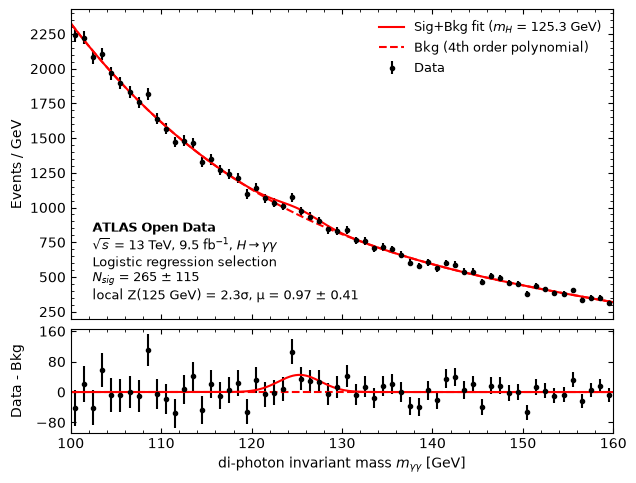

In [8]:
fig = plot_fit(extra["fit"], title="Logistic regression selection", lumi=LUMI_TEST,
               label_extra=f"local Z(125 GeV) = {res['Z_obs']:.1f}σ, μ = {res['mu']:.2f} ± {res['mu_err']:.2f}")
plt.savefig(FIG_DIR / "logreg_myy_fit.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
save("logreg", sc, res)
print("saved scores and summary to results/scores/")

saved scores and summary to results/scores/


## Notes
- The quoted significance is **local** (signal mass fixed to 125 GeV, Wilks' theorem with one parameter of interest); no look-elsewhere correction.
- Systematic uncertainties (photon energy scale/resolution, luminosity, theory cross-section, background-function choice) are not included: errors are statistical only.
- The comparison with the tutorial cuts and the boosted tree is in `05_global_comparison.ipynb`.